In [ ]:
#Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

sns.set_style("whitegrid")

In [ ]:
# Loading Dataset

In [2]:
df = pd.read_csv('hospital_directory (1).csv',dtype=str)
df = df.sample(5000, random_state=1)
df.head()

,Sr_No,Location_Coordinates,Location,Hospital_Name,Hospital_Category,Hospital_Care_Type,Discipline_Systems_of_Medicine,Address_Original_First_Line,State,District,...,Number_Doctor,Num_Mediconsultant_or_Expert,Total_Num_Beds,Number_Private_Wards,Num_Bed_for_Eco_Weaker_Sec,Empanelment_or_Collaboration_with,Emergency_Services,Tariff_Range,State_ID,District_ID
11222,12995,"12.9141417, 74.8559568","Punjalkatte, Belthangady Tq, Mangalore",Bhats Clinic and Day Care Centre,0,0,0,"Punjalkatte, Belthangady Tq, Mangalore",Karnataka,Dakshina Kannada,...,0,0,0,0,0,0,0,0,29,575
9047,10821,NaN,"OppositeHousing Board Colony,Phase-3,Sai Rqad,...",Gupta Surgical Hospitaland Maternity Home,0,0,0,"OppositeHousing Board Colony,Phase-3,Sai Rqad,...",Himachal Pradesh,Solan,...,0,0,0,0,0,0,0,0,2,31
6399,8173,NaN,"3Rd Floor, Pramukh Doctor House, Near Auto Poi...",Nilesh Children Hospital,0,0,0,"3Rd Floor, Pramukh Doctor House, Near Auto Poi...",Gujarat,Surat,...,0,0,0,0,0,0,0,0,24,492
1292,1294,NaN,"Ramchandra Rao Pet,.",Lokendra Nursing Home,0,0,0,Ramchandra Rao Pet,Andhra Pradesh,West Godavari,...,0,0,0,0,0,0,0,0,28,546
21727,23503,NaN,"88, Shakti Nagar",Kota Eye Hospital And Research Foundation,0,0,0,"88 , Shakti Nagar",Rajasthan,Kota,...,0,0,0,0,0,0,0,0,8,127


In [ ]:
# Basic Checks

In [3]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 11222 to 405
Data columns (total 48 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   Sr_No                              5000 non-null   object
 1   Location_Coordinates               1789 non-null   object
 2   Location                           5000 non-null   object
 3   Hospital_Name                      5000 non-null   object
 4   Hospital_Category                  5000 non-null   object
 5   Hospital_Care_Type                 5000 non-null   object
 6   Discipline_Systems_of_Medicine     5000 non-null   object
 7   Address_Original_First_Line        4926 non-null   object
 8   State                              5000 non-null   object
 9   District                           5000 non-null   object
 10  Subdistrict                        5000 non-null   object
 11  Pincode                            5000 non-null   object
 12  Telephon

Sr_No                                   0
Location_Coordinates                 3211
Location                                0
Hospital_Name                           0
Hospital_Category                       0
Hospital_Care_Type                      0
Discipline_Systems_of_Medicine          0
Address_Original_First_Line            74
State                                   0
District                                0
Subdistrict                             0
Pincode                                 0
Telephone                               0
Mobile_Number                           1
Emergency_Num                          10
Ambulance_Phone_No                      0
Bloodbank_Phone_No                      0
Foreign_pcare                           0
Tollfree                                0
Helpline                                0
Hospital_Fax                            2
Hospital_Primary_Email_Id              27
Hospital_Secondary_Email_Id             9
Website                           

In [ ]:
# removing unnecessary columns

In [4]:
remove_cols = []

for col in df.columns:
    if "name" in col.lower() or "address" in col.lower() or "phone" in col.lower():
        remove_cols.append(col)

df = df.drop(columns=remove_cols)
df.head()

,Sr_No,Location_Coordinates,Location,Hospital_Category,Hospital_Care_Type,Discipline_Systems_of_Medicine,State,District,Subdistrict,Pincode,...,Number_Doctor,Num_Mediconsultant_or_Expert,Total_Num_Beds,Number_Private_Wards,Num_Bed_for_Eco_Weaker_Sec,Empanelment_or_Collaboration_with,Emergency_Services,Tariff_Range,State_ID,District_ID
11222,12995,"12.9141417, 74.8559568","Punjalkatte, Belthangady Tq, Mangalore",0,0,0,Karnataka,Dakshina Kannada,0,574233,...,0,0,0,0,0,0,0,0,29,575
9047,10821,NaN,"OppositeHousing Board Colony,Phase-3,Sai Rqad,...",0,0,0,Himachal Pradesh,Solan,0,173205,...,0,0,0,0,0,0,0,0,2,31
6399,8173,NaN,"3Rd Floor, Pramukh Doctor House, Near Auto Poi...",0,0,0,Gujarat,Surat,0,395010,...,0,0,0,0,0,0,0,0,24,492
1292,1294,NaN,"Ramchandra Rao Pet,.",0,0,0,Andhra Pradesh,West Godavari,0,534002,...,0,0,0,0,0,0,0,0,28,546
21727,23503,NaN,"88, Shakti Nagar",0,0,0,Rajasthan,Kota,0,324009,...,0,0,0,0,0,0,0,0,8,127


In [ ]:
# Exploratory Data Analysis (EDA)

In [ ]:
#State Wise Hospital Count 

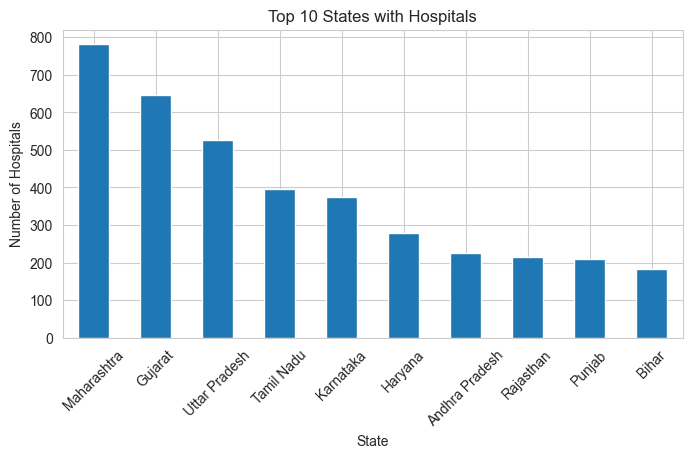

In [5]:
plt.figure(figsize=(8, 4))
df["State"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 States with Hospitals")
plt.xlabel("State")
plt.ylabel("Number of Hospitals")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Hospital category distrubutions

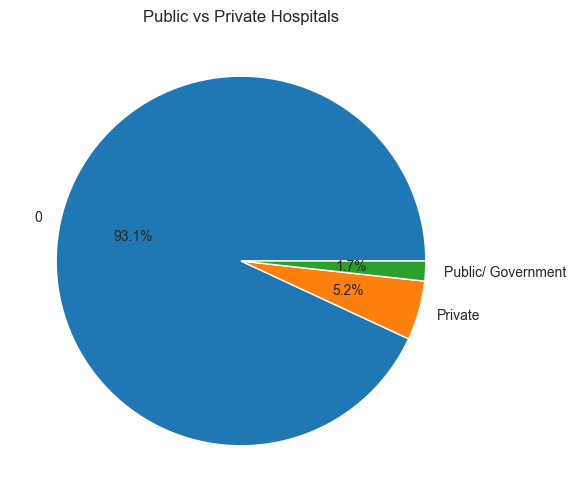

In [6]:
plt.figure(figsize=(6, 6))
df["Hospital_Category"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Public vs Private Hospitals")
plt.ylabel("")
plt.show()

In [ ]:
#Public vs Private hospitals in top 5 states

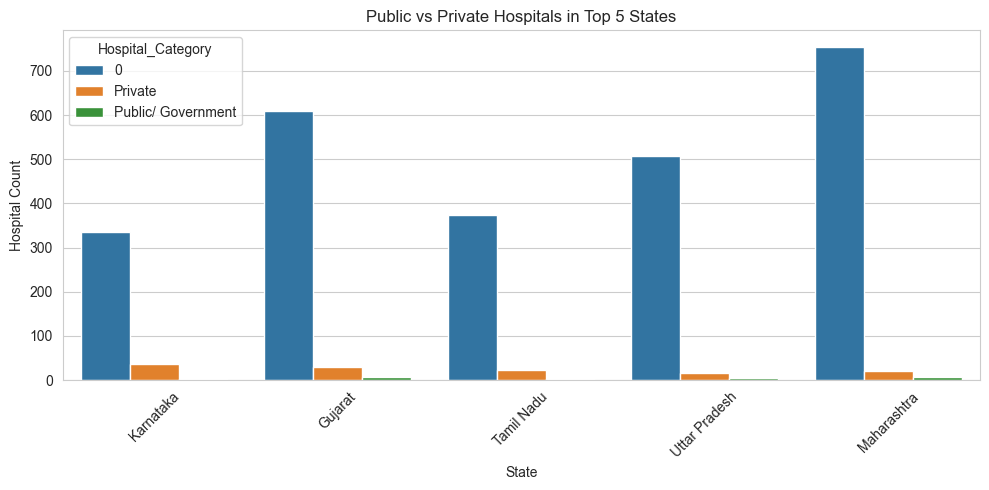

In [7]:
top_states = df["State"].value_counts().head(5).index

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df[df["State"].isin(top_states)],
    x="State",
    hue="Hospital_Category"
)
plt.title("Public vs Private Hospitals in Top 5 States")
plt.xlabel("State")
plt.ylabel("Hospital Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# District-wise hospital density(Top 10)

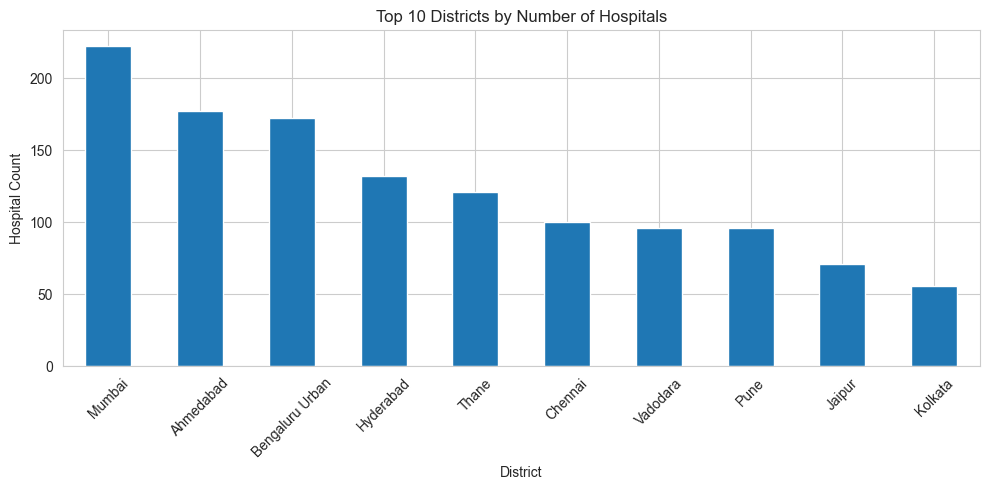

In [8]:
plt.figure(figsize=(10, 5))
df["District"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Districts by Number of Hospitals")
plt.xlabel("District")
plt.ylabel("Hospital Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#selecting Features

In [9]:
df_ml = df[
    [
        "State",
        "District",
        "Discipline_Systems_of_Medicine",
        "Ayush",
        "Hospital_Category"
    ]
]

df_ml = df_ml.dropna()

In [ ]:
# Encoding categorical coloumns

In [10]:
le = LabelEncoder()
for col in df_ml.columns:
    df_ml[col] = le.fit_transform(df_ml[col].astype(str))

In [ ]:
# splitting data

In [11]:
X = df_ml.drop("Hospital_Category", axis=1)
y = df_ml["Hospital_Category"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [ ]:
#scaling features

In [12]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Training Models

In [13]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5),
    "Random Forest": RandomForestClassifier(max_depth=5),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVM": SVC()
}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average="weighted", zero_division=0)
    rec = recall_score(y_test, preds, average="weighted", zero_division=0)
    f1 = f1_score(y_test, preds, average="weighted", zero_division=0)

    print("\nModel:", name)
    print("Accuracy :", round(acc, 3))
    print("Precision:", round(prec, 3))
    print("Recall   :", round(rec, 3))
    print("F1 Score :", round(f1, 3))


Model: Decision Tree
Accuracy : 0.985
Precision: 0.982
Recall   : 0.985
F1 Score : 0.981

Model: Random Forest
Accuracy : 0.986
Precision: 0.983
Recall   : 0.986
F1 Score : 0.982

Model: KNN
Accuracy : 0.986
Precision: 0.983
Recall   : 0.986
F1 Score : 0.983

Model: SVM
Accuracy : 0.984
Precision: 0.971
Recall   : 0.984
F1 Score : 0.977


In [ ]:
# Accuracy comparison plot

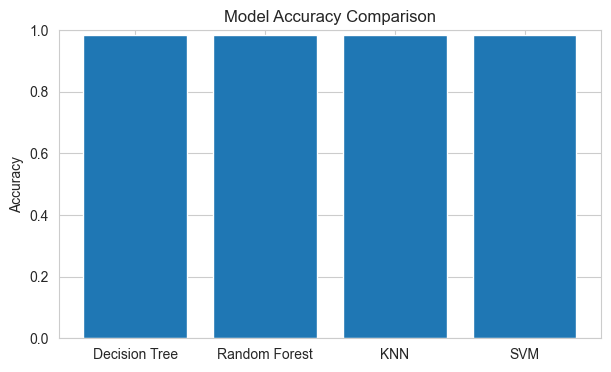

In [14]:

acc_values = []
for model in models.values():
    preds = model.predict(X_test)
    acc_values.append(accuracy_score(y_test, preds))
    
plt.figure(figsize=(7, 4))
plt.bar(models.keys(), acc_values)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()